# 01 · Combine and clean the data

We build one clean, labelled dataset of films from the two Kaggle *TMDB Box Office Prediction* files.

Kaggle never released revenues for `tmdb_test.csv`, and its training file is small (3,000 films). We therefore combine both files and label every film with its worldwide gross from an IMDb dataset (`top_movies.feather`), matched by IMDb id. We then remove unreliable labels, adjust money to 2025 dollars, and make our own train / validation / test split.

**Output:** `movies_clean.parquet`, used by notebooks 02 and 03.

1. Imports
2. Load the raw files
3. Combine train and test
4. Look up the latest revenue
5. Remove junk amounts
6. Fix known bad labels
7. Remove unusable films
8. Adjust for inflation
9. Keep only relevant columns
10. Train / validation / test split
11. Check the split
12. Save

## 1. Imports

In [ ]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cpi                
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the raw files

In [4]:
train = pd.read_csv("tmdb_train.csv")
test = pd.read_csv("tmdb_test.csv")
imdb = pd.read_feather("top_movies.feather", columns=["id", "gross_worldwide"])

print(f"tmdb_train: {train.shape}")
print(f"tmdb_test:  {test.shape}")
print(f"top_movies: {imdb.shape}")
print("Columns only in train:", set(train.columns) - set(test.columns))

tmdb_train: (3000, 23)
tmdb_test:  (4398, 22)
top_movies: (63249, 2)
Columns only in train: {'revenue'}


## 3. Combine train and test

`revenue` exists only in the train file. We rename it `revenue_tmdb_2019` (the Kaggle snapshot); it is empty for test films. `orig_split` records which file each film came from.

Release dates are `m/d/yy`. The data ends in 2018, so two-digit years `00`–`18` are 2000s and the rest are 1900s.

In [5]:
train["orig_split"] = "train"
test["orig_split"] = "test"

df = pd.concat([train, test], ignore_index=True)
df = df.rename(columns={"revenue": "revenue_tmdb_2019"})
assert df["imdb_id"].is_unique

parts = df["release_date"].str.split("/", expand=True).astype(float)
yy = parts[2]
df["year"] = np.where(yy <= 18, 2000 + yy, 1900 + yy)
df.loc[yy.isna(), "year"] = np.nan
df["release_date"] = pd.to_datetime(dict(year=df["year"], month=parts[0], day=parts[1]), errors="coerce")

print(f"Combined: {df.shape}")
df["orig_split"].value_counts()

Combined: (7398, 25)


orig_split
test     4398
train    3000
Name: count, dtype: int64

## 4. Look up the latest revenue

The IMDb dataset stores worldwide gross as text such as `$27,399,597`. We keep USD values only.

In [6]:
def parse_usd(s):
    """'$27,399,597' -> 27399597.0; non-USD or missing -> NaN."""
    if not isinstance(s, str) or not s.startswith("$"):
        return np.nan
    digits = re.sub(r"[^\d]", "", s)
    return float(digits) if digits else np.nan


imdb["revenue_latest"] = imdb["gross_worldwide"].map(parse_usd)
df = df.merge(imdb[["id", "revenue_latest"]], left_on="imdb_id", right_on="id",
              how="left", suffixes=("", "_imdb")).drop(columns="id_imdb")

df.groupby("orig_split")["revenue_latest"].agg(films="size", with_latest_revenue="count")

,films,with_latest_revenue
orig_split,,
test,4398,3906
train,3000,2652


## 5. Remove junk amounts

TMDB records an unknown budget as 0, and some budgets and revenues are recorded as 1, 12, 113, … (typos or amounts in millions). Amounts below **$10,000** are treated as missing.

In [7]:
MIN_AMOUNT = 10_000

for c in ["budget", "revenue_tmdb_2019", "revenue_latest"]:
    df[c] = df[c].where(df[c] >= MIN_AMOUNT)

df.groupby("orig_split")[["budget", "revenue_tmdb_2019", "revenue_latest"]].count()

,budget,revenue_tmdb_2019,revenue_latest
orig_split,,,
test,3152,0,3845
train,2165,2908,2604


## 6. Fix known bad labels

For original train films we have two revenue figures: the 2019 TMDB value and the latest IMDb gross. Most agree closely. Where they disagree, the direction depends on the era:

- **IMDb much higher:** the 2019 TMDB value was incomplete; we keep the IMDb gross.
- **IMDb much lower** (ratio < 0.5): IMDb often records only a re-release or partial gross, especially for older and Indian films. We use the 2019 TMDB value instead.

Our label `revenue` is the IMDb gross, except for those films; `revenue_source` records which source was used.

In [8]:
ratio = df["revenue_latest"] / df["revenue_tmdb_2019"]
both = ratio.notna()
log_ratio = np.log10(ratio[both])

print(f"Films with both revenues: {both.sum():,}")
print(f"Median ratio (IMDb / TMDB): {ratio[both].median():.3f}")
print(f"Within 10%:            {(log_ratio.abs() < np.log10(1.1)).mean():.1%}")
print(f"Within a factor of 2:  {(log_ratio.abs() < np.log10(2)).mean():.1%}")

Films with both revenues: 2,556
Median ratio (IMDb / TMDB): 1.000
Within 10%:            73.9%
Within a factor of 2:  87.6%


In [7]:
era = pd.cut(df["year"], [1900, 1979, 1999, 2020], labels=["before 1980", "1980-1999", "2000+"])
direction = np.select([ratio > 2, ratio < 0.5], ["IMDb much higher", "IMDb much lower"], "agree")
pd.crosstab(era[both].rename("era"), pd.Series(direction, index=df.index, name="IMDb vs TMDB")[both], margins=True)

IMDb vs TMDB,IMDb much higher,IMDb much lower,agree,All
era,,,,
before 1980,3,35,88,126
1980-1999,19,21,805,845
2000+,216,24,1345,1585
All,238,80,2238,2556


In [9]:
df["revenue"] = df["revenue_latest"]
df["revenue_source"] = np.where(df["revenue"].notna(), "imdb", None)

bad_imdb = ratio < 0.5
df.loc[bad_imdb, "revenue"] = df.loc[bad_imdb, "revenue_tmdb_2019"]
df.loc[bad_imdb, "revenue_source"] = "tmdb_2019"

print(f"Labels replaced by the 2019 TMDB value: {bad_imdb.sum()}")

Labels replaced by the 2019 TMDB value: 80


## 7. Remove unusable films

| Reason | Why |
|---|---|
| No revenue | No usable label. This includes train films with only a 2019 TMDB revenue: we keep a single label source rather than mix sources for small films. |
| Released before 1980 | About 28% of the checkable pre-1980 films have an IMDb gross far too low (a re-release figure), and the rest cannot be checked. Old films also matter little for forecasting new releases. |
| Unknown release year | Needed for inflation and the split. |
| Not released | A few films are marked "Rumored" or "Post Production" rather than "Released". |

In [10]:
MIN_YEAR = 1980

reason = pd.Series(np.select(
    [df["revenue"].isna(), df["year"].isna(), df["year"] < MIN_YEAR, df["status"] != "Released"],
    ["no revenue", "unknown year", f"before {MIN_YEAR}", "not released"],
    "kept",
), index=df.index, name="reason")

display(pd.crosstab(reason, df["orig_split"], margins=True))

df = df[reason == "kept"].reset_index(drop=True)
print(f"Films kept: {len(df):,}   years {df['year'].min():.0f}–{df['year'].max():.0f}")

orig_split,test,train,All
reason,,,
before 1980,220,130,350
kept,3618,2472,6090
no revenue,553,396,949
not released,7,2,9
All,4398,3000,7398


Films kept: 6,090   years 1980–2017


## 8. Adjust for inflation

We convert budget and revenue to **2025 US dollars** with the US consumer price index, using each film's release year. Both get the same factor, since a film's budget is spent and most of its revenue is earned within a year or two of release; ROI is therefore unchanged.

This is approximate in two ways: it applies US inflation to worldwide revenue, and it applies the release-year factor to lifetime gross, which can include later re-releases.

Our modelling target is `log_revenue_cpi` = ln(1 + revenue in 2025 dollars).

In [11]:
factor = df["year"].map({y: cpi.inflate(1.0, int(y), 2025) for y in df["year"].unique()})

df["budget_cpi"] = df["budget"] * factor
df["revenue_cpi"] = df["revenue"] * factor
df["log_budget_cpi"] = np.log1p(df["budget_cpi"])
df["log_revenue_cpi"] = np.log1p(df["revenue_cpi"])
df["roi"] = df["revenue"] / df["budget"]

pd.Series({y: cpi.inflate(1.0, y, 2025) for y in [1980, 1990, 2000, 2010, 2017]}).round(2).rename("2025 dollars per dollar")

1980    3.91
1990    2.46
2000    1.87
2010    1.48
2017    1.31
Name: 2025 dollars per dollar, dtype: float64

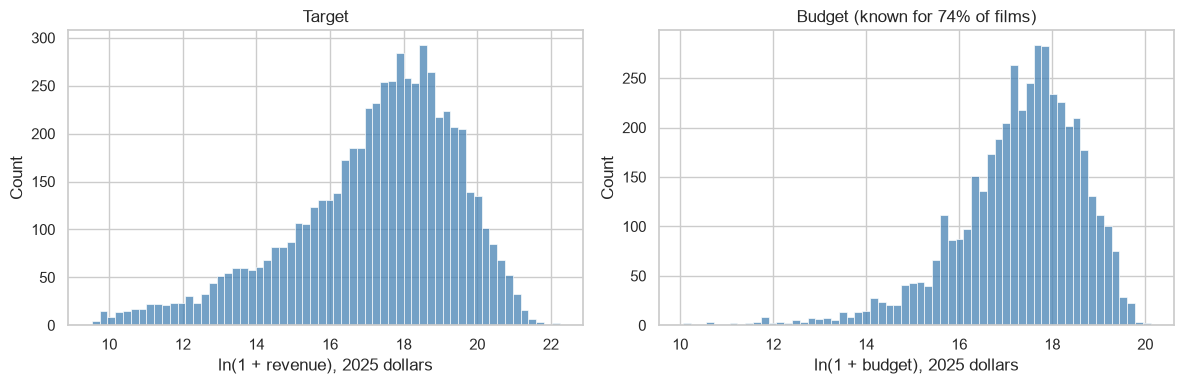

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["log_revenue_cpi"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_xlabel("ln(1 + revenue), 2025 dollars")
axes[0].set_title("Target")
sns.histplot(df["log_budget_cpi"].dropna(), bins=60, ax=axes[1], color="steelblue")
axes[1].set_xlabel("ln(1 + budget), 2025 dollars")
axes[1].set_title(f"Budget (known for {df['budget'].notna().mean():.0%} of films)")
plt.tight_layout()

## 9. Keep only relevant columns

We drop columns that are irrelevant to the prediction or not known before release. Raw list columns (`cast`, `crew`, `Keywords`, …) stay as text; notebook 02 turns them into features.

| Dropped | Why |
|---|---|
| `id` | Kaggle row number |
| `original_title` | Duplicates `title` |
| `homepage`, `tagline` | Recorded on TMDB after release, more often for well-known films |
| `popularity` | Measured long after release |
| `poster_path` | Image link only |
| `status` | All remaining films are released |
| `revenue_latest` | Kept as `revenue` (after the fixes in section 6) |

In [13]:
keep = [
    # identifiers and split bookkeeping
    "imdb_id", "title", "orig_split",
    # release
    "release_date", "year",
    # film attributes (raw; parsed in notebook 02)
    "runtime", "original_language", "genres", "production_companies", "production_countries",
    "spoken_languages", "belongs_to_collection", "Keywords", "overview", "cast", "crew",
    # money
    "budget", "budget_cpi", "log_budget_cpi",
    "revenue", "revenue_source", "revenue_tmdb_2019", "revenue_cpi", "log_revenue_cpi", "roi",
]
df = df[keep]
df.shape

(6090, 25)

## 10. Train / validation / test split

70 / 15 / 15, stratified by release decade so each part spans the same years. Notebook 03 uses train + validation for cross-validation and the test films once, at the end.

In [14]:
SEED = 42

decade = (df["year"] // 10 * 10).astype(int).astype(str) + "s"
# first split into train (70) and rest (30) 
idx_train, idx_rest = train_test_split(df.index, test_size=0.30, stratify=decade, random_state=SEED)
# second split of rest (30) into validation (15) and test (15)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=decade[idx_rest], random_state=SEED)

df["split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"

df["split"].value_counts().reindex(["train", "val", "test"])

split
train    4263
val       913
test      914
Name: count, dtype: int64

## 11. Check the split

In [15]:
df.groupby("split").agg(
    films=("imdb_id", "size"),
    median_year=("year", "median"),
    median_revenue_musd_2025=("revenue_cpi", lambda s: s.median() / 1e6),
    budget_known=("budget", lambda s: s.notna().mean()),
    median_roi=("roi", "median"),
    from_kaggle_test=("orig_split", lambda s: (s == "test").mean()),
).reindex(["train", "val", "test"]).round(2)

,films,median_year,median_revenue_musd_2025,budget_known,median_roi,from_kaggle_test
split,,,,,,
train,4263,2005.0,43.55,0.74,2.03,0.59
val,913,2005.0,48.26,0.72,2.27,0.59
test,914,2005.0,48.63,0.74,2.04,0.62


In [16]:
pd.crosstab(decade, df["split"]).reindex(columns=["train", "val", "test"])

split,train,val,test
year,,,
1980s,583,125,125
1990s,882,189,189
2000s,1429,306,307
2010s,1369,293,293


## 12. Save

In [17]:
df.to_parquet("movies_clean.parquet", index=False)
print(f"Saved movies_clean.parquet: {df.shape}")

Saved movies_clean.parquet: (6090, 26)
